In [1]:
import pandas as pd

df = pd.read_csv('dataset.csv')

#check if all values are unique
print(df['Gene_Name'].is_unique)
print(df.info())

#rename columns
df.rename(columns={'FPKM_Stroke_5Days_Adipocytes': "disorder", 'FPKM_Control_5Days_Adipocytes': "control"}, inplace=True)
df.info()


False
<class 'pandas.DataFrame'>
RangeIndex: 997 entries, 0 to 996
Data columns (total 4 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Track_id                       997 non-null    str    
 1   Gene_Name                      997 non-null    str    
 2   FPKM_Control_5Days_Adipocytes  997 non-null    float64
 3   FPKM_Stroke_5Days_Adipocytes   997 non-null    float64
dtypes: float64(2), str(2)
memory usage: 31.3 KB
None
<class 'pandas.DataFrame'>
RangeIndex: 997 entries, 0 to 996
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Track_id   997 non-null    str    
 1   Gene_Name  997 non-null    str    
 2   control    997 non-null    float64
 3   disorder   997 non-null    float64
dtypes: float64(2), str(2)
memory usage: 31.3 KB


/var/folders/73/b0btw3bd7rn_53l7vz7cn0w40000gn/T/ipykernel_89834/3862064223.py:10: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={'FPKM_Stroke_5Days_Adipocytes': "disorder", 'FPKM_Control_5Days_Adipocytes': "control"}, inplace=True)


In [2]:
df.head()

,Track_id,Gene_Name,control,disorder
0,ENSMUSG00000022034.9,Esco2,1.184760,0.047183
1,ENSMUSG00000024598.8,Fbn2,0.595342,0.035866
2,ENSMUSG00000037016.11,Frem2,0.312452,0.028501
3,ENSMUSG00000037225.13,Fgf2,16.852009,1.605054
4,ENSMUSG00000038754.4,Elovl3,0.572404,0.063533


In [3]:
import numpy as np

criteria = np.log2(df['disorder']/df['control'])
criteria_bool = criteria > 1

upreg_idx = criteria_bool[criteria_bool == True].index.tolist()
upreg_genes = df.loc[upreg_idx, 'Gene_Name'].tolist()

print(f"Upregulated genes: {upreg_genes}")
print(f"Number of upregulated genes: {len(upreg_idx)}")

#Search for function of upregulated genes





Upregulated genes: ['Ephx1', 'Ffar4', 'Ethe1', 'Fam19a5', 'Eci3', 'Fam183b', 'Egfl6', 'Fam188b', 'Foxp1', 'Ear2', 'Fam84a', 'F13b', 'Flt3l', 'Fbxo21', 'Fbxo36', 'Eif4ebp3', 'Erich4', 'Flt3', 'Enho', 'Eva1c', 'Fam71e1', 'Folh1', 'Far1', 'Foxf1', 'Fut4', 'Epn3', 'Fam134c', 'Faah', 'Fgf9', 'Fgf21', 'Fcgr4', 'Elane', 'F7', 'Foxf2', 'Fam178b', 'Fabp2', 'Fam3b', 'Fcrla', 'Fbxo47', 'Fcamr', 'Fam151a', 'Edn3', 'Erc2', 'Esrp2', 'Extl1', 'Fam83b', 'Foxa2', 'Fpr1', 'Fpr2']
Number of upregulated genes: 49


/Users/hubvarith/miniforge3/envs/ea231/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


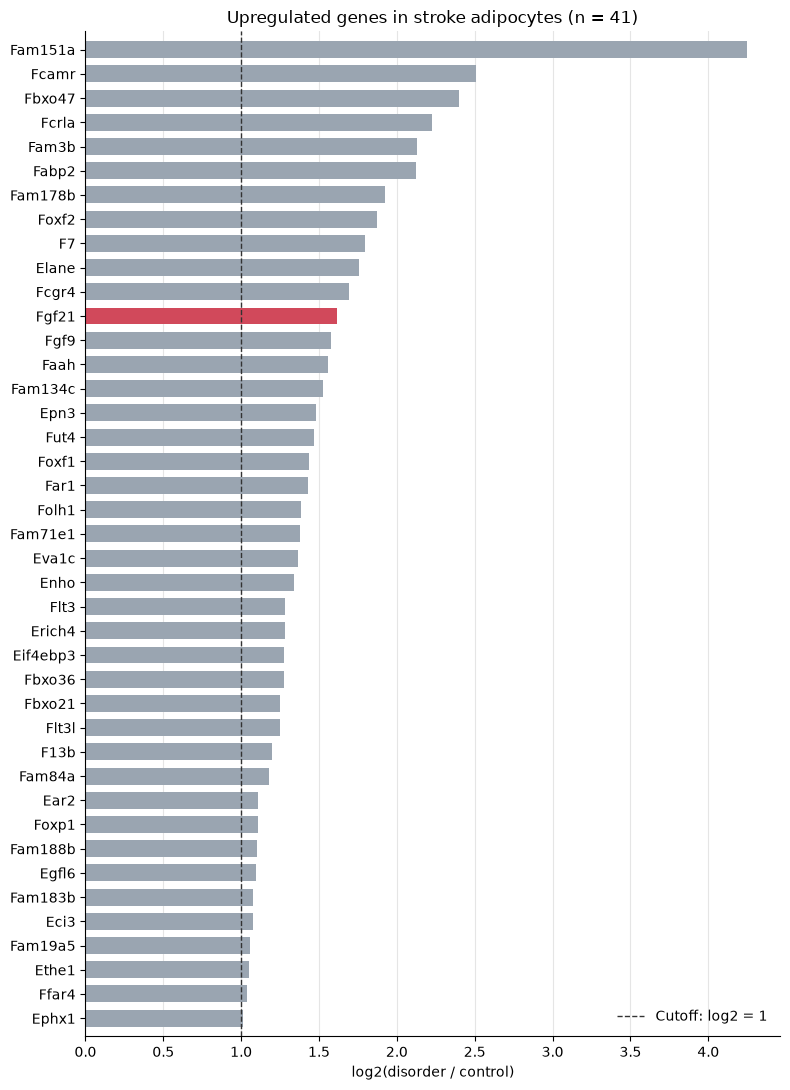

Not plotted (control = 0, infinite ratio): ['Edn3', 'Erc2', 'Esrp2', 'Extl1', 'Fam83b', 'Foxa2', 'Fpr1', 'Fpr2']


In [4]:
import matplotlib.pyplot as plt

# Genes with control = 0 give an infinite ratio, so they cannot be plotted.
upreg = df.loc[upreg_idx, ['Gene_Name', 'control', 'disorder']].copy()
upreg['log2_fc'] = criteria[upreg_idx]
infinite_genes = upreg.loc[~np.isfinite(upreg['log2_fc']), 'Gene_Name'].tolist()
upreg = upreg[np.isfinite(upreg['log2_fc'])].sort_values('log2_fc')

bar_colors = ['#d1495b' if gene == 'Fgf21' else '#9aa5b1' for gene in upreg['Gene_Name']]

fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(upreg['Gene_Name'], upreg['log2_fc'], color=bar_colors, height=0.7)
ax.axvline(1, color='#333333', linestyle='--', linewidth=1, label='Cutoff: log2 = 1')
ax.set_xlabel('log2(disorder / control)')
ax.set_title(f'Upregulated genes in stroke adipocytes (n = {len(upreg)})')
ax.grid(axis='x', color='#e5e5e5')
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.margins(y=0.01)
ax.legend(loc='lower right', frameon=False)
plt.tight_layout()
plt.show()

print(f"Not plotted (control = 0, infinite ratio): {infinite_genes}")


In [5]:
import requests

rows = []
for gene in upreg['Gene_Name']:
    response = requests.get(
        'https://rest.uniprot.org/uniprotkb/search',
        params={
            'query': f'gene_exact:{gene} AND organism_id:10090 AND reviewed:true',
            'fields': 'gene_primary,cc_subcellular_location,cc_function',
            'format': 'json',
        },
        timeout=30,
    )
    if not response.ok:
        print(f"Warning: UniProt request failed for {gene} (status {response.status_code})")
        rows.append({'gene': gene, 'location': 'request failed', 'function': ''})
        continue

    results = response.json()['results']
    if not results:
        rows.append({'gene': gene, 'location': 'not found', 'function': ''})
        continue

    comments = results[0].get('comments', [])
    location = ''
    function = ''
    for comment in comments:
        if comment['commentType'] == 'SUBCELLULAR LOCATION':
            location = ', '.join(loc['location']['value'] for loc in comment.get('subcellularLocations', []))
        if comment['commentType'] == 'FUNCTION':
            function = comment['texts'][0]['value']
    rows.append({'gene': gene, 'location': location, 'function': function})

annotations = pd.DataFrame(rows)
secreted = annotations[annotations['location'].str.contains('Secreted')]

print(f"Secreted proteins: {len(secreted)} of {len(annotations)} upregulated genes")
pd.set_option('display.max_colwidth', None)
secreted


Secreted proteins: 9 of 41 upregulated genes


,gene,location,function
3,Fam19a5,Secreted,"Acts as a chemokine-like protein by regulating cell proliferation and migration through activation of G protein-coupled receptors (GPCRs), such as S1PR2 and FPR2 (PubMed:29138422, PubMed:29453251). Stimulates chemotactic migration of macrophages mediated by the MAPK3/ERK1 and AKT1 pathway (PubMed:29138422). Blocks TNFSF11/RANKL-induced osteoclast formation from macrophages by inhibiting up-regulation of osteoclast fusogenic and differentiation genes (PubMed:29138422). Stimulation of macrophage migration and inhibition of osteoclast formation is mediated through the GPCR FPR2 (PubMed:29138422). Acts as an adipokine by negatively regulating vascular smooth muscle cell (VSMC) proliferation and migration in response to platelet-derived growth factor stimulation via GPCR S1PR2 and G protein GNA12/GNA13-transmitted RHOA signaling (By similarity). Inhibits injury-induced cell proliferation and neointima formation in the femoral arteries (PubMed:29453251)"
6,Egfl6,"Secreted, extracellular space, extracellular matrix, basement membrane",May bind integrin alpha-8/beta-1 and play a role in hair follicle morphogenesis. Promotes matrix assembly
11,F13b,Secreted,"The B chain of factor XIII is not catalytically active, but is thought to stabilize the A subunits and regulate the rate of transglutaminase formation by thrombin"
12,Flt3l,Secreted,"Stimulates the proliferation of early hematopoietic cells by activating FLT3. Synergizes well with a number of other colony stimulating factors and interleukins. Essential for the development of natural killer (NK) cells, B cells, and dendritic cells (DCs)"
18,Enho,Secreted,Involved in the regulation of glucose homeostasis and lipid metabolism
28,Fgf9,Secreted,"Plays an important role in the regulation of embryonic development, cell proliferation, cell differentiation and cell migration. May have a role in glial cell growth and differentiation during development, gliosis during repair and regeneration of brain tissue after damage, differentiation and survival of neuronal cells, and growth stimulation of glial tumors"
29,Fgf21,Secreted,Stimulates glucose uptake in differentiated adipocytes via the induction of glucose transporter SLC2A1/GLUT1 expression (but not SLC2A4/GLUT4 expression). Activity probably requires the presence of KLB. Regulates systemic glucose homeostasis and insulin sensitivity
32,F7,Secreted,"Initiates the extrinsic pathway of blood coagulation. Serine protease that circulates in the blood in a zymogen form. Factor VII is converted to factor VIIa by factor Xa, factor XIIa, factor IXa, or thrombin by minor proteolysis. In the presence of tissue factor and calcium ions, factor VIIa then converts factor X to factor Xa by limited proteolysis. Factor VIIa also converts factor IX to factor IXa in the presence of tissue factor and calcium (By similarity)"
36,Fam3b,Secreted,Induces apoptosis of alpha and beta cells in a dose- and time-dependent manner
